# CBAM-ResNet18 + GASF — Pilot 5 Epoch (metode pembanding)

**Status: BELUM DIJALANKAN.** Notebook dibuat tanpa akses Drive/GPU. Semua flag default `False`.

**Bukan reproduksi exact** Ma, Zhan & Yang (2022), *Biomed. Signal Process. Control* 77:103684, DOI `10.1016/j.bspc.2022.103684`. Eksperimen ini adalah metode pembanding yang terinspirasi dari paper tersebut. Paper memakai CWGAN-GP dan segmen 2.5 detik @360 Hz; di sini dipakai pipeline 187-titik proyek, **tanpa CWGAN-GP**.

Angka paper (Acc 99.23%, Avg Precision 99.13%, Sens 97.50%, Spec 99.81%, Avg F1 98.29%) **tidak diverifikasi** dan hanya referensi. Paper juga memiliki corrigendum (BSPC 77:103834) yang belum saya baca.

Baseline proyek: ResNet18+GAF, Acc 98.86 / Macro P 95.23 / Macro R 91.97 / Macro F1 93.53.
**Perhatian:** baseline dipilih pada test set dan memakai SMOTE (152.471 sampel). Pilot ini memakai training split mentah 70.043 sampel dengan class weight. Lihat catatan di akhir.

**Urutan wajib:** smoke test → pilot 5 epoch → keputusan → full training 25 epoch hanya jika PROMISING → test sekali.

In [38]:
# ===== CONFIG & FLAGS =====
import os
import json
RUN_SMOKE_TEST = False
RUN_PILOT = False
RUN_FULL_TRAINING = False
RUN_FINAL_EVALUATION = True
RESUME = True

SEED = 42
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"
DATA_CSV = os.path.join(BASE_DIR, "data", "mitbih_train.csv")
FEAT_DIR = os.path.join(BASE_DIR, "features")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
CKPT_RUN_DIR = os.path.join(CKPT_DIR, "cbam_gasf")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")
FIG_DIR = os.path.join(BASE_DIR, "outputs", "figures")

N_FEAT, N_CLASSES = 187, 5
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
EXPECTED_TRAIN_COUNTS = {0: 72471, 1: 2223, 2: 5788, 3: 641, 4: 6431}
EXPECTED_TEST_COUNTS = {0: 18118, 1: 556, 2: 1448, 3: 162, 4: 1608}

VAL_SIZE = 0.2
BATCH_SIZE = 64
EPOCHS_PILOT = 5
EPOCHS_FULL = 25
CLASS_WEIGHTS = [1.0, 2.0, 1.0, 2.0, 1.0]     # sama dengan baseline
LR_BACKBONE = 1e-4                             # layer3, layer4, CBAM, fc0
LR_FC2 = 1e-3
LR_FC4 = 2e-3
ADAM_BETAS = (0.5, 0.999)
SCHED_GAMMA = 0.95
GASF_IMAGE_SIZE = 150
IMG_SIZE = 224
CBAM_REDUCTION = 16    # standard CBAM
CBAM_SPATIAL_KERNEL = 7  # standard CBAM

PILOT_TOLERANCE_PP = 1.0   # heuristik screening; pilot tidak menjadi klaim kemenangan

BASELINE = {"accuracy": 98.86, "macro_precision": 95.23, "macro_recall": 91.97, "macro_f1": 93.53}

SELECTION_METRIC = "macro_recall"  # primary checkpoint-selection metric
PILOT_DECISION = None
COMPARISON_DECISION = None
FINAL = None
SMOKE_STATUS = None

In [39]:
# ===== ENVIRONMENT =====
# Jika pyts belum ada, jalankan sekali: !pip install -q pyts
import random, time, math, sys, platform
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from pyts.image import GramianAngularField
import pyts
from google.colab import drive

drive.mount("/content/drive")
for d in (CKPT_DIR, CKPT_RUN_DIR, RESULTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
ENV = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "pyts": pyts.__version__,
    "sklearn": sklearn.__version__, "cuda": torch.version.cuda, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
}
print(ENV)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'pyts': '0.14.1', 'sklearn': '1.6.1', 'cuda': '13.0', 'device': 'cuda', 'gpu': 'Tesla T4'}


## 1. Data (raw train CSV + test dari features)

In [40]:
raw = pd.read_csv(DATA_CSV, header=None)
assert raw.shape == (87554, N_FEAT + 1), f"Shape CSV tidak sesuai: {raw.shape}. Cek header."
X_raw = raw.iloc[:, :N_FEAT].to_numpy(dtype=np.float32)
y_raw = raw.iloc[:, N_FEAT].to_numpy().astype(np.int64)
del raw
assert dict(sorted(Counter(y_raw.tolist()).items())) == EXPECTED_TRAIN_COUNTS

X_test = np.load(os.path.join(FEAT_DIR, "X_test.npy")).astype(np.float32)
y_test = np.load(os.path.join(FEAT_DIR, "y_test.npy")).astype(np.int64)
assert X_test.shape == (21892, N_FEAT) and y_test.shape == (21892,)
assert dict(sorted(Counter(y_test.tolist()).items())) == EXPECTED_TEST_COUNTS
print("train raw", X_raw.shape, "| test", X_test.shape, "| dataset dicek")

train raw (87554, 187) | test (21892, 187) | dataset dicek


## 2. Split 80/20 stratified (train raw). Tanpa oversampling/SMOTE: pilot memakai class weight baseline.

In [41]:
idx_tr, idx_va = train_test_split(np.arange(len(y_raw)), test_size=VAL_SIZE,
                                  stratify=y_raw, random_state=42)
print("training split  :", len(idx_tr), "| validation split:", len(idx_va))
print("train counts    :", dict(sorted(Counter(y_raw[idx_tr].tolist()).items())))
print("validation counts:", dict(sorted(Counter(y_raw[idx_va].tolist()).items())))

class IndexedArrayDataset(Dataset):
    def __init__(self, X, y, idx):
        self.X, self.y, self.idx = X, y, np.asarray(idx)
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.X[j], int(self.y[j])

train_ds = IndexedArrayDataset(X_raw, y_raw, idx_tr)
val_ds = IndexedArrayDataset(X_raw, y_raw, idx_va)
test_ds = IndexedArrayDataset(X_test, y_test, np.arange(len(y_test)))

training split  : 70043 | validation split: 17511
train counts    : {0: 57977, 1: 1778, 2: 4630, 3: 513, 4: 5145}
validation counts: {0: 14494, 1: 445, 2: 1158, 3: 128, 4: 1286}


## 3. GASF (on-the-fly, per batch, deterministik)
GASF `image_size=150`, `method="summation"`, resize ke 224×224, lalu 1 channel → 3 channel (`repeat`), sama seperti baseline.

**Catatan:** pyts men-downsample 187 titik ke 150 dengan PAA (dugaan dari dokumentasi; diverifikasi di smoke test). Baseline GAF memakai `image_size=150` yang sama, sehingga langkah ini konsisten.

**Asumsi:** metode resize (bilinear) disamakan dengan baseline; belum diverifikasi terhadap cell resize di notebook `01_replikasi`.

In [42]:
gasf_sum = GramianAngularField(image_size=GASF_IMAGE_SIZE, method="summation")

def gasf_batch(X):
    """X: (B,187) numpy float32 -> tensor (B,3,224,224). Transformasi per sampel, tanpa fitting pada data."""
    img = gasf_sum.fit_transform(X)                       # (B,150,150), pyts scale per sampel
    t = torch.from_numpy(img.astype(np.float32)).unsqueeze(1)
    t = F.interpolate(t, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return t.repeat(1, 3, 1, 1)

def collate_gasf(batch):
    xs = np.stack([b[0] for b in batch]).astype(np.float32)
    ys = torch.tensor([b[1] for b in batch], dtype=torch.long)
    return gasf_batch(xs), ys

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_gasf, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_gasf, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_gasf, num_workers=0)

In [43]:
# ===== SAMPLE CHECK (1 sampel) =====
if RUN_SMOKE_TEST:
    one = X_raw[idx_tr[:1]]
    print("input (187,)       :", one[0].shape)
    g = GramianAngularField(image_size=GASF_IMAGE_SIZE, method="summation").fit_transform(one)[0]
    print("GASF raw shape     :", g.shape)
    t = gasf_batch(one)
    print("after resize       :", tuple(t.shape), "| finite:", bool(torch.isfinite(t).all()))
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].plot(one[0]); ax[0].set_title("ECG 187 titik")
    ax[1].imshow(g, cmap="rainbow"); ax[1].set_title("GASF 150x150")
    fig.tight_layout(); plt.show()
else:
    print("NOT RUN: set RUN_SMOKE_TEST = True untuk sample check GASF")

NOT RUN: set RUN_SMOKE_TEST = True untuk sample check GASF


## 4. CBAM (standard) dan CBAM-ResNet18
- CBAM = channel attention (avg+max pool, shared MLP, sigmoid) lalu spatial attention (mean+max channel, conv 7×7, sigmoid).
- CBAM ditempatkan setelah `layer1..layer4` (struktur dari spesifikasi).
- Backbone: freeze semua, unfreeze `layer3` dan `layer4` (sama dengan baseline).
- **Asumsi:** modul CBAM baru (random init) dibuat trainable, termasuk yang berada di `layer1`/`layer2` yang backbone-nya frozen. Jika tidak, atensi tidak akan belajar.

In [44]:
class ChannelAttention(nn.Module):
    def __init__(self, c, r=CBAM_REDUCTION):
        super().__init__()
        hid = max(c // r, 1)
        self.mlp = nn.Sequential(nn.Conv2d(c, hid, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(hid, c, 1, bias=False))
    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1))
        m = self.mlp(F.adaptive_max_pool2d(x, 1))
        return x * torch.sigmoid(a + m)

class SpatialAttention(nn.Module):
    def __init__(self, k=CBAM_SPATIAL_KERNEL):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        s = torch.cat([x.mean(dim=1, keepdim=True), x.amax(dim=1, keepdim=True)], dim=1)
        return x * torch.sigmoid(self.conv(s))

class CBAM(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ca = ChannelAttention(c)
        self.sa = SpatialAttention()
    def forward(self, x):
        return self.sa(self.ca(x))

def build_cbam_resnet():
    net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for p in net.parameters():
        p.requires_grad = False
    net.layer1 = nn.Sequential(net.layer1, CBAM(64))
    net.layer2 = nn.Sequential(net.layer2, CBAM(128))
    net.layer3 = nn.Sequential(net.layer3, CBAM(256))
    net.layer4 = nn.Sequential(net.layer4, CBAM(512))
    for p in net.layer3[0].parameters(): p.requires_grad = True
    for p in net.layer4[0].parameters(): p.requires_grad = True
    cbam_params = []
    for stage in (net.layer1, net.layer2, net.layer3, net.layer4):
        for p in stage[1].parameters():
            p.requires_grad = True
            cbam_params.append(p)
    net.fc = nn.Sequential(
        nn.Linear(512, 256, bias=False), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, 5),
    )
    return net, cbam_params

probe, _ = build_cbam_resnet()
N_PARAMS_TOTAL = sum(p.numel() for p in probe.parameters())
N_PARAMS_TRAINABLE = sum(p.numel() for p in probe.parameters() if p.requires_grad)
print(f"CBAM-ResNet18 total={N_PARAMS_TOTAL:,} | trainable={N_PARAMS_TRAINABLE:,}")
print("Baseline ResNet18+GAF total = 11,341,125")
del probe

CBAM-ResNet18 total=11,385,037 | trainable=10,701,965
Baseline ResNet18+GAF total = 11,341,125


## 5. Loss, optimizer (sama dengan baseline), scheduler, metrik
Optimizer groups baseline: layer3, layer4, fc0 = 1e-4; fc2 = 1e-3; fc4 = 2e-3. **Asumsi:** parameter CBAM masuk ke grup 1e-4 (tanpa hyperparameter baru).

In [45]:
def build_training(net, cbam_params):
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.Adam([
        {"params": net.layer3[0].parameters(), "lr": LR_BACKBONE},
        {"params": net.layer4[0].parameters(), "lr": LR_BACKBONE},
        {"params": cbam_params, "lr": LR_BACKBONE},
        {"params": net.fc[0].parameters(), "lr": LR_BACKBONE},
        {"params": net.fc[2].parameters(), "lr": LR_FC2},
        {"params": net.fc[4].parameters(), "lr": LR_FC4},
    ], betas=ADAM_BETAS)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=SCHED_GAMMA)
    return criterion, optimizer, scheduler

def compute_metrics(y_true, y_pred):
    return {
        "accuracy": 100 * accuracy_score(y_true, y_pred),
        "macro_precision": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

@torch.no_grad()
def evaluate(net, loader, criterion):
    net.eval()
    loss_sum, n, ys, ps = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        out = net(xb)
        loss_sum += criterion(out, yb).item() * len(yb)
        n += len(yb)
        ys.append(yb.cpu().numpy()); ps.append(out.argmax(1).cpu().numpy())
    return loss_sum / n, np.concatenate(ys), np.concatenate(ps)

def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    loss_sum, n, ys, ps = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        out = net(xb)
        loss = criterion(out, yb)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss non-finite: {loss.item()}")
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(yb); n += len(yb)
        ys.append(yb.cpu().numpy()); ps.append(out.argmax(1).detach().cpu().numpy())
    y_true, y_pred = np.concatenate(ys), np.concatenate(ps)
    return loss_sum / n, compute_metrics(y_true, y_pred)

## 6. Smoke test (1 batch, tanpa test)

In [46]:
def smoke_test():
    st = {}
    set_seed(SEED)
    net, cbam_params = build_cbam_resnet()
    net = net.to(DEVICE)
    criterion, optimizer, _ = build_training(net, cbam_params)
    xb, yb = next(iter(train_loader))
    st["DATA LOADER + GASF"] = "PASS" if tuple(xb.shape[1:]) == (3, IMG_SIZE, IMG_SIZE) else "FAIL"
    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    st["INPUT SHAPE"] = str(tuple(xb.shape))
    net.train()
    out = net(xb)
    st["OUTPUT SHAPE"] = "PASS" if tuple(out.shape) == (len(xb), N_CLASSES) else "FAIL"
    loss = criterion(out, yb)
    st["LOSS"] = "PASS" if bool(torch.isfinite(loss)) else "FAIL"
    optimizer.zero_grad(); loss.backward()
    grads_ok = all(p.grad is not None and bool(torch.isfinite(p.grad).all())
                   for p in net.parameters() if p.requires_grad)
    st["GRADIENTS FINITE"] = "PASS" if grads_ok else "FAIL"
    before = [p.detach().clone() for p in net.parameters() if p.requires_grad]
    optimizer.step()
    after = [p.detach() for p in net.parameters() if p.requires_grad]
    st["OPTIMIZER STEP"] = "PASS" if any(not torch.equal(b, a) for b, a in zip(before, after)) else "FAIL"
    return st

if RUN_SMOKE_TEST:
    SMOKE_STATUS = smoke_test()
    print(pd.Series(SMOKE_STATUS, name="status").to_string())
else:
    print("NOT RUN: set RUN_SMOKE_TEST = True")

NOT RUN: set RUN_SMOKE_TEST = True


## 7. Fit (resumable, checkpoint terbaik = validation macro F1)

In [47]:
def fit(num_epochs, tag, best_path, last_path):
    set_seed(SEED)
    net, cbam_params = build_cbam_resnet()
    net = net.to(DEVICE)
    criterion, optimizer, scheduler = build_training(net, cbam_params)
    history, best_score, start = [], -float("inf"), 1

    if RESUME and os.path.exists(last_path):
        st = torch.load(last_path, map_location=DEVICE, weights_only=False)
        net.load_state_dict(st["model"]); optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        history = st["history"]
        best_score = float(st.get("best_score", st.get("best_val_macro_recall", -float("inf"))))
        start = st["epoch"] + 1
        print(f"RESUME {tag} dari epoch {st['epoch']} | best {SELECTION_METRIC}={best_score:.4f}")

    for epoch in range(start, num_epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = train_one_epoch(net, train_loader, criterion, optimizer)
        va_loss, yt, yp = evaluate(net, val_loader, criterion)
        va_m = compute_metrics(yt, yp)
        scheduler.step()
        dur = time.time() - t0
        row = {"epoch": epoch,
               "train_loss": tr_loss, "train_accuracy": tr_m["accuracy"],
               "train_macro_precision": tr_m["macro_precision"], "train_macro_recall": tr_m["macro_recall"],
               "train_macro_f1": tr_m["macro_f1"],
               "val_loss": va_loss, "val_accuracy": va_m["accuracy"],
               "val_macro_precision": va_m["macro_precision"], "val_macro_recall": va_m["macro_recall"],
               "val_macro_f1": va_m["macro_f1"], "epoch_time_s": dur}
        history.append(row)

        score = float(va_m[SELECTION_METRIC])
        if score > best_score:
            best_score = score
            torch.save({"epoch": epoch, "model": net.state_dict(), "val_metrics": va_m,
                        "selection_metric": SELECTION_METRIC, "best_score": best_score}, best_path)

        torch.save({"epoch": epoch, "model": net.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "history": history,
                    "selection_metric": SELECTION_METRIC, "best_score": best_score,
                    "best_val_macro_recall": max(r["val_macro_recall"] for r in history)}, last_path)
        pd.DataFrame(history).to_csv(os.path.join(RESULTS_DIR, f"cbam_gasf_history_{tag}.csv"), index=False)
        print(f"[{tag}] ep {epoch}/{num_epochs} | tr_loss {tr_loss:.4f} tr_acc {tr_m['accuracy']:.2f} "
              f"tr_mRec {tr_m['macro_recall']:.2f} tr_mF1 {tr_m['macro_f1']:.2f} | "
              f"va_loss {va_loss:.4f} va_acc {va_m['accuracy']:.2f} "
              f"va_mRec {va_m['macro_recall']:.2f} va_mF1 {va_m['macro_f1']:.2f} | {dur:.0f}s")
    return pd.DataFrame(history)

PILOT_BEST = os.path.join(CKPT_DIR, "cbam_gasf_pilot_best.pt")
PILOT_LAST = os.path.join(CKPT_RUN_DIR, "pilot_last.pt")
FULL_BEST = os.path.join(CKPT_RUN_DIR, "full_best_validation_macro_recall.pt")
FULL_LAST = os.path.join(CKPT_RUN_DIR, "full_last.pt")

if RUN_PILOT:
    pilot_hist = fit(EPOCHS_PILOT, "pilot", PILOT_BEST, PILOT_LAST)
    pilot_hist.to_csv(os.path.join(RESULTS_DIR, "cbam_gasf_pilot_history.csv"), index=False)
else:
    print("NOT RUN: set RUN_PILOT = True")


NOT RUN: set RUN_PILOT = True


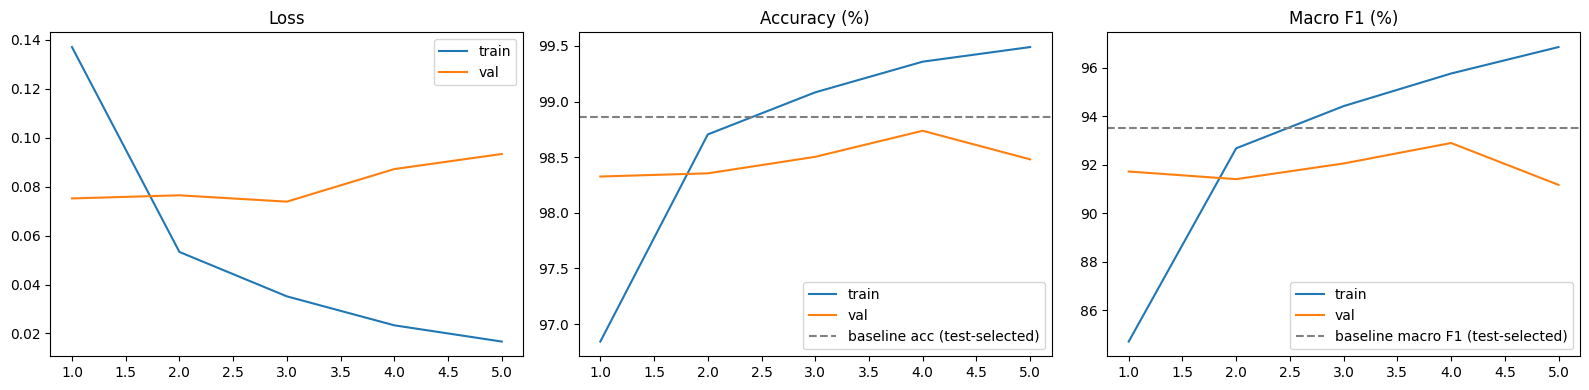

In [48]:
hp = os.path.join(RESULTS_DIR, "cbam_gasf_pilot_history.csv")
if os.path.exists(hp):
    h = pd.read_csv(hp)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_accuracy, label="train"); ax[1].plot(h.epoch, h.val_accuracy, label="val")
    ax[1].axhline(BASELINE["accuracy"], ls="--", color="gray", label="baseline acc (test-selected)")
    ax[1].set_title("Accuracy (%)"); ax[1].legend()
    ax[2].plot(h.epoch, h.train_macro_f1, label="train"); ax[2].plot(h.epoch, h.val_macro_f1, label="val")
    ax[2].axhline(BASELINE["macro_f1"], ls="--", color="gray", label="baseline macro F1 (test-selected)")
    ax[2].set_title("Macro F1 (%)"); ax[2].legend()
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "cbam_gasf_pilot_curve.png"), dpi=150); plt.show()
else:
    print("Belum ada history pilot.")

## 8. Keputusan pilot
Pilot sudah menunjukkan bahwa **Validation Macro Recall** adalah metrik kandidat yang paling relevan untuk screening, karena target tugas hanya mensyaratkan minimal satu parameter lebih tinggi dari baseline.

Untuk full training, checkpoint terbaik akan dipilih berdasarkan **Validation Macro Recall**, bukan Macro F1. Ini bukan klaim kemenangan; keputusan final tetap berdasarkan test 21.892 setelah training selesai.

Batas screening menggunakan toleransi 1.0 percentage point terhadap baseline Macro Recall hanya sebagai heuristik agar eksperimen yang jelas tidak menjanjikan dapat dihentikan lebih awal.


In [49]:
hp = os.path.join(RESULTS_DIR, "cbam_gasf_pilot_history.csv")
if os.path.exists(hp):
    h = pd.read_csv(hp)
    bi = h["val_macro_recall"].idxmax()
    best = h.loc[bi]
    best_recall = float(best["val_macro_recall"])
    best_acc = float(h["val_accuracy"].max())
    improving = len(h) >= 2 and best_recall > float(h["val_macro_recall"].iloc[0])
    near = best_recall >= BASELINE["macro_recall"] - PILOT_TOLERANCE_PP
    PILOT_DECISION = "PROMISING" if (near and improving) else "NOT PROMISING"
    print("BEST PILOT VALIDATION (dipilih berdasarkan val macro recall)")
    print(f"  epoch           : {int(best['epoch'])}")
    print(f"  accuracy        : {best['val_accuracy']:.2f}")
    print(f"  macro precision : {best['val_macro_precision']:.2f}")
    print(f"  macro recall    : {best['val_macro_recall']:.2f}")
    print(f"  macro F1        : {best['val_macro_f1']:.2f}")
    print(f"  best val acc (any epoch): {best_acc:.2f}")
    print("DECISION (pilot, recall screening only):", PILOT_DECISION)
else:
    print("NOT RUN: belum ada history pilot.")


BEST PILOT VALIDATION (dipilih berdasarkan val macro recall)
  epoch           : 5
  accuracy        : 98.48
  macro precision : 89.39
  macro recall    : 93.30
  macro F1        : 91.17
  best val acc (any epoch): 98.74
DECISION (pilot, recall screening only): PROMISING


## 9. Full training 25 epoch (terkunci, hanya jika PROMISING)

In [50]:
if RUN_FULL_TRAINING:
    if PILOT_DECISION != "PROMISING":
        raise RuntimeError("Full training diblokir: keputusan pilot bukan PROMISING atau pilot belum dijalankan.")
    full_hist = fit(EPOCHS_FULL, "full", FULL_BEST, FULL_LAST)
    full_hist.to_csv(os.path.join(RESULTS_DIR, "cbam_gasf_history.csv"), index=False)
else:
    print("NOT RUN: full training terkunci (RUN_FULL_TRAINING = False)")

NOT RUN: full training terkunci (RUN_FULL_TRAINING = False)


## 10. Final evaluation pada test (sekali)
Memuat checkpoint full dengan **Validation Macro Recall** terbaik. Test hanya dipakai di sini.


{'accuracy': 98.4652, 'macro_precision': 89.6226, 'macro_recall': 92.1795, 'macro_f1': 90.5251, 'checkpoint_epoch': 5.0, 'inference_time_per_sample_ms': 1.906}


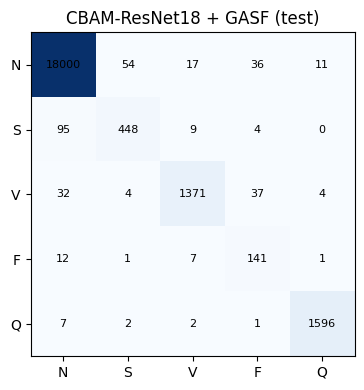

In [51]:
if RUN_FINAL_EVALUATION:
    if not os.path.exists(FULL_BEST):
        raise FileNotFoundError("Checkpoint full belum ada.")
    st = torch.load(FULL_BEST, map_location=DEVICE, weights_only=False)
    net, _ = build_cbam_resnet()
    net.load_state_dict(st["model"]); net = net.to(DEVICE)
    criterion, _, _ = build_training(net, [])
    t0 = time.time()
    _, yt, yp = evaluate(net, test_loader, criterion)
    infer_s = time.time() - t0

    FINAL = compute_metrics(yt, yp)
    FINAL["checkpoint_epoch"] = st["epoch"]
    FINAL["inference_time_per_sample_ms"] = 1000 * infer_s / len(yt)
    print({k: round(float(v), 4) for k, v in FINAL.items()})

    pd.DataFrame([FINAL]).to_csv(os.path.join(RESULTS_DIR, "cbam_gasf_test_metrics.csv"), index=False)
    rep = classification_report(yt, yp, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(rep).T.to_csv(os.path.join(RESULTS_DIR, "cbam_gasf_classification_report.csv"))
    cm = confusion_matrix(yt, yp, labels=range(N_CLASSES))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        os.path.join(RESULTS_DIR, "cbam_gasf_confusion_matrix.csv"))
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(5)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticks(range(5)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax.set_title("CBAM-ResNet18 + GASF (test)")
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "cbam_gasf_confusion_matrix.png"), dpi=150); plt.show()
else:
    print("NOT RUN: set RUN_FINAL_EVALUATION = True setelah full training")

## 11. Perbandingan dengan baseline
Perbandingan final di test tetap ketat: candidate harus **lebih tinggi** (`>`) pada minimal satu metric untuk dianggap lebih baik. Tidak ada toleransi.


In [52]:
if FINAL is not None:
    rows = []
    for key, label in [("accuracy", "Accuracy"), ("macro_precision", "Macro Precision"),
                       ("macro_recall", "Macro Recall"), ("macro_f1", "Macro F1")]:
        rows.append({"metric": label, "baseline_resnet18_gaf": BASELINE[key],
                     "cbam_gasf": FINAL[key], "difference_pp": FINAL[key] - BASELINE[key]})
    comp = pd.DataFrame(rows)
    comp.to_csv(os.path.join(RESULTS_DIR, "cbam_gasf_vs_baseline.csv"), index=False)
    print(comp.round(4).to_string(index=False))
    superior = any(FINAL[k] > BASELINE[k] for k in BASELINE)
    COMPARISON_DECISION = "SUPERIOR ON AT LEAST ONE METRIC" if superior else "DOES NOT EXCEED BASELINE"
    print("\nDECISION:", COMPARISON_DECISION)
else:
    print("NOT RUN: belum ada evaluasi final.")

         metric  baseline_resnet18_gaf  cbam_gasf  difference_pp
       Accuracy                  98.86    98.4652        -0.3948
Macro Precision                  95.23    89.6226        -5.6074
   Macro Recall                  91.97    92.1795         0.2095
       Macro F1                  93.53    90.5251        -3.0049

DECISION: SUPERIOR ON AT LEAST ONE METRIC


In [53]:
hp = os.path.join(RESULTS_DIR, "cbam_gasf_pilot_history.csv")
pilot_duration = float(pd.read_csv(hp)["epoch_time_s"].sum()) if os.path.exists(hp) else "NOT RUN"
efficiency = {
    "cbam_total_params": N_PARAMS_TOTAL,
    "cbam_trainable_params": N_PARAMS_TRAINABLE,
    "baseline_total_params": 11341125,
    "pilot_duration_s": pilot_duration,
    "inference_time_per_sample_ms": FINAL["inference_time_per_sample_ms"] if FINAL else "NOT RUN",
}
log = {
    "paper": "Ma, Zhan, Yang 2022, BSPC 77:103684, DOI 10.1016/j.bspc.2022.103684 (inspirasi; bukan replikasi exact)",
    "paper_reported_UNVERIFIED": {"accuracy": 99.23, "avg_precision": 99.13, "sensitivity": 97.50,
                                  "specificity": 99.81, "avg_f1": 98.29},
    "paper_corrigendum": "BSPC 77:103834 (belum dibaca)",
    "deviations": ["no CWGAN-GP", "187-point pipeline, not 2.5 s @360 Hz", "GASF 150 via pyts PAA",
                   "class-weighted loss, no oversampling/SMOTE", "stratified 80/20 train/validation"],
    "assumptions": ["CBAM standard (reduction 16, spatial kernel 7)", "CBAM placed after layer1..layer4",
                    "CBAM params trainable and in lr 1e-4 group", "resize bilinear (match baseline unverified)",
                    "ExponentialLR stepped once per epoch", f"pilot recall-screening tolerance {PILOT_TOLERANCE_PP} pp"],
    "baseline_caveats": ["baseline checkpoint selected on test set",
                         "baseline trained on SMOTE train (152,471), candidate on raw train split (70,043)",
                         "baseline per-class class weights identical"],
    "environment": ENV, "seed": SEED,
    "flags": {"RUN_SMOKE_TEST": RUN_SMOKE_TEST, "RUN_PILOT": RUN_PILOT,
              "RUN_FULL_TRAINING": RUN_FULL_TRAINING, "RUN_FINAL_EVALUATION": RUN_FINAL_EVALUATION},
    "smoke_status": SMOKE_STATUS, "pilot_decision": PILOT_DECISION,
    "comparison_decision": COMPARISON_DECISION, "final_test_metrics": FINAL,
    "selection_metric": SELECTION_METRIC,
    "efficiency": efficiency,
}
with open(os.path.join(RESULTS_DIR, "cbam_gasf_experiment_log.json"), "w") as f:
    json.dump(log, f, indent=2, default=str)
print("Log tersimpan.")

Log tersimpan.


In [54]:
print("=" * 40)
print("CBAM-RESNET + GASF — RECALL-SELECTION PILOT")
print("=" * 40)
print("NOTEBOOK: 09_cbam_gasf_pilot_recall_selection.ipynb\n")
print("BASELINE")
print("--------")
print(f"Accuracy       : {BASELINE['accuracy']}%")
print(f"Macro Precision: {BASELINE['macro_precision']}%")
print(f"Macro Recall   : {BASELINE['macro_recall']}%")
print(f"Macro F1       : {BASELINE['macro_f1']}%\n")
hp = os.path.join(RESULTS_DIR, "cbam_gasf_pilot_history.csv")
print("BEST PILOT VALIDATION (PRIMARY = MACRO RECALL)")
print("-----------------------------------------------")
if os.path.exists(hp):
    h = pd.read_csv(hp); b = h.loc[h["val_macro_recall"].idxmax()]
    print(f"Accuracy       : {b['val_accuracy']:.2f}")
    print(f"Macro Precision: {b['val_macro_precision']:.2f}")
    print(f"Macro Recall   : {b['val_macro_recall']:.2f}")
    print(f"Macro F1       : {b['val_macro_f1']:.2f}")
    print(f"Epoch          : {int(b['epoch'])}\n")
else:
    print("NOT RUN\n")
print("SMOKE TEST:", ("NOT RUN" if not SMOKE_STATUS else ("PASS" if all(v == "PASS" for k, v in SMOKE_STATUS.items() if k != "INPUT SHAPE") else "FAIL")))
print("PILOT DECISION:", PILOT_DECISION or "NOT RUN")
print("FULL TRAINING :", "RUN" if RUN_FULL_TRAINING else "NOT RUN")
print("FULL CHECKPOINT SELECTION:", SELECTION_METRIC)


CBAM-RESNET + GASF — RECALL-SELECTION PILOT
NOTEBOOK: 09_cbam_gasf_pilot_recall_selection.ipynb

BASELINE
--------
Accuracy       : 98.86%
Macro Precision: 95.23%
Macro Recall   : 91.97%
Macro F1       : 93.53%

BEST PILOT VALIDATION (PRIMARY = MACRO RECALL)
-----------------------------------------------
Accuracy       : 98.48
Macro Precision: 89.39
Macro Recall   : 93.30
Macro F1       : 91.17
Epoch          : 5

SMOKE TEST: NOT RUN
PILOT DECISION: PROMISING
FULL TRAINING : NOT RUN
FULL CHECKPOINT SELECTION: macro_recall


## Catatan (wajib dibaca)
1. **Bukan replikasi exact.** Tanpa CWGAN-GP, pipeline 187-titik proyek, dan GASF 150 dengan PAA dari pyts.
2. **Baseline tidak sebanding penuh.** (a) checkpoint baseline dipilih pada test set; (b) baseline dilatih pada SMOTE train 152.471 sampel, sedangkan pilot ini memakai training split mentah 70.043 sampel dengan class weight. Perbedaan ini dapat memengaruhi angka. Kalau ingin isolasi efek GASF+CBAM, bandingkan juga dengan GAF+ResNet18 pada training split yang sama.
3. **Angka paper tidak diverifikasi.** Paper memiliki corrigendum yang belum saya baca.
4. **Tidak ada klaim superior sebelum test.** Keputusan pilot hanya untuk melanjutkan atau menghentikan.